# Milestone 04: PatchCore Feature-Memory Anomaly Detection (EfficientNetB0)

In Milestones 02 and 03, we proved that pixel-level autoencoders hit a fundamental glass ceiling on rigid mechanical objects like `metal_nut` (achieving 25.61% -> 31.67% AUROC). Because natural rotational variations and metallic glares create massive pixel differences, healthy rotated nuts produce larger raw reconstruction errors than real microscopic scratches.

### The PatchCore Solution (Roth et al., CVPR 2022)
1. **Pre-trained CNN:** Instead of reconstructing raw pixels, we pass images through an ImageNet-pretrained `EfficientNetB0`.
2. **Multi-Scale Patches:** We extract intermediate patch feature representations from mid-level layers (`block2b_add` and `block3b_add`), enriched with local neighborhood pooling.
3. **Memory Bank:** We store healthy patch representations in a Memory Bank and subsample them into a compact Core-Set (10%).
4. **Nearest-Neighbor Scoring:** At test time, an image is scored by the distance of its patches to healthy memory: if any patch is far from healthy textures, it is flagged as an anomaly.

In [3]:
import os, sys
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import roc_auc_score, roc_curve

# 1. Ensure project root is in working directory and sys.path
if Path.cwd().name == "notebooks":
    os.chdir("..")
project_root = Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# 2. Set random seeds for reproducible coreset sampling
tf.random.set_seed(42)
np.random.seed(42)

# 3. Import our custom VisionGuard modules
from src.models.efficientnet import MultiScaleFeatureExtractor
from src.models.feature_memory import PatchCoreMemoryBank
from src.data.loader import create_autoencoder_datasets, create_test_dataset, get_image_paths
from src.inference.localization import generate_heatmap_and_overlay

CATEGORY = "metal_nut"
print(f"Working Directory:  {project_root}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Target Category:    {CATEGORY}")

Working Directory:  d:\Data Science\projects\VisionGuard-AI
TensorFlow Version: 2.21.0
Target Category:    metal_nut


## 1. Fit the PatchCore Memory Bank on Nominal Training Data

We stream the healthy training images through the EfficientNetB0 extractor.
Each image produces 32 × 32 = 1,024 patches of dimension 64. We then apply
Coreset Subsampling (10%) to keep only the most representative patch vectors.

In [4]:
# Load nominal training dataset
train_ds, val_ds, n_train, n_val = create_autoencoder_datasets(
    category=CATEGORY, batch_size=16, val_split=0.15, random_seed=42
)
print(f"Loaded {n_train} training samples for [{CATEGORY}]")

# Initialize extractor and memory bank
extractor = MultiScaleFeatureExtractor(input_shape=(256, 256, 3))
memory_bank = PatchCoreMemoryBank(feature_extractor=extractor, coreset_ratio=0.10)

# Fit — takes ~15-25 seconds (frozen weights, no backprop)
print("\nFitting Core-Set Memory Bank...")
start_time = time.time()
memory_bank.fit(train_ds)
fit_duration = time.time() - start_time

print(f"\nDone in {fit_duration:.2f} seconds!")
print(f"Memory Bank Shape: {memory_bank.memory_bank.shape}")
print(f"Stored Vectors: {memory_bank.memory_bank.shape[0]:,} (Dimension: {memory_bank.memory_bank.shape[1]})")

Loaded 187 training samples for [metal_nut]


Fitting Core-Set Memory Bank...

Done in 3.74 seconds!
Memory Bank Shape: (19148, 64)
Stored Vectors: 19,148 (Dimension: 64)


In [5]:
# 1. Load test images, binary labels (0=good, 1=defect), and ground-truth masks
test_ds, _, _ = create_test_dataset(category=CATEGORY, batch_size=16)

test_imgs, test_lbls, test_masks = [], [], []
for img_b, lbl_b, mask_b in test_ds:
    test_imgs.append(img_b.numpy())
    test_lbls.append(lbl_b.numpy())
    test_masks.append(mask_b.numpy())

test_imgs = np.concatenate(test_imgs, axis=0)
test_lbls = np.concatenate(test_lbls, axis=0)
test_masks = np.squeeze(np.concatenate(test_masks, axis=0), axis=-1)  # (N, 256, 256)

# 2. Score every test image using your fitted memory_bank
patchcore_scores = []
patchcore_maps = []
latencies_ms = []

for img in test_imgs:
    t0 = time.perf_counter()
    score, hmap = memory_bank.score_image(img, gaussian_kernel=7, sigma=1.5)
    latencies_ms.append((time.perf_counter() - t0) * 1000.0)
    patchcore_scores.append(score)
    patchcore_maps.append(hmap)

patchcore_scores = np.array(patchcore_scores)
patchcore_maps = np.array(patchcore_maps)

# 3. Calculate Image-Level AUROC and Pixel-Level AUROC
img_auroc = roc_auc_score(test_lbls, patchcore_scores)
pix_auroc = roc_auc_score((test_masks > 0.5).astype(np.int32).ravel(), patchcore_maps.ravel())

norm_scores = patchcore_scores[test_lbls == 0]
def_scores = patchcore_scores[test_lbls == 1]

print(f"Normal Test Scores  : n={len(norm_scores)}  mean={norm_scores.mean():.4f} (+/-{norm_scores.std():.4f})")
print(f"Defect Test Scores  : n={len(def_scores)}  mean={def_scores.mean():.4f} (+/-{def_scores.std():.4f})")
print(f"Image-Level AUROC   : {img_auroc * 100:.2f}%")
print(f"Pixel-Level AUROC   : {pix_auroc * 100:.2f}%")
print(f"Avg Inference Time  : {np.mean(latencies_ms):.2f} ms/image")

Normal Test Scores  : n=22  mean=19.5819 (+/-1.1241)
Defect Test Scores  : n=93  mean=25.7483 (+/-3.4721)
Image-Level AUROC   : 95.89%
Pixel-Level AUROC   : 98.31%
Avg Inference Time  : 137.84 ms/image


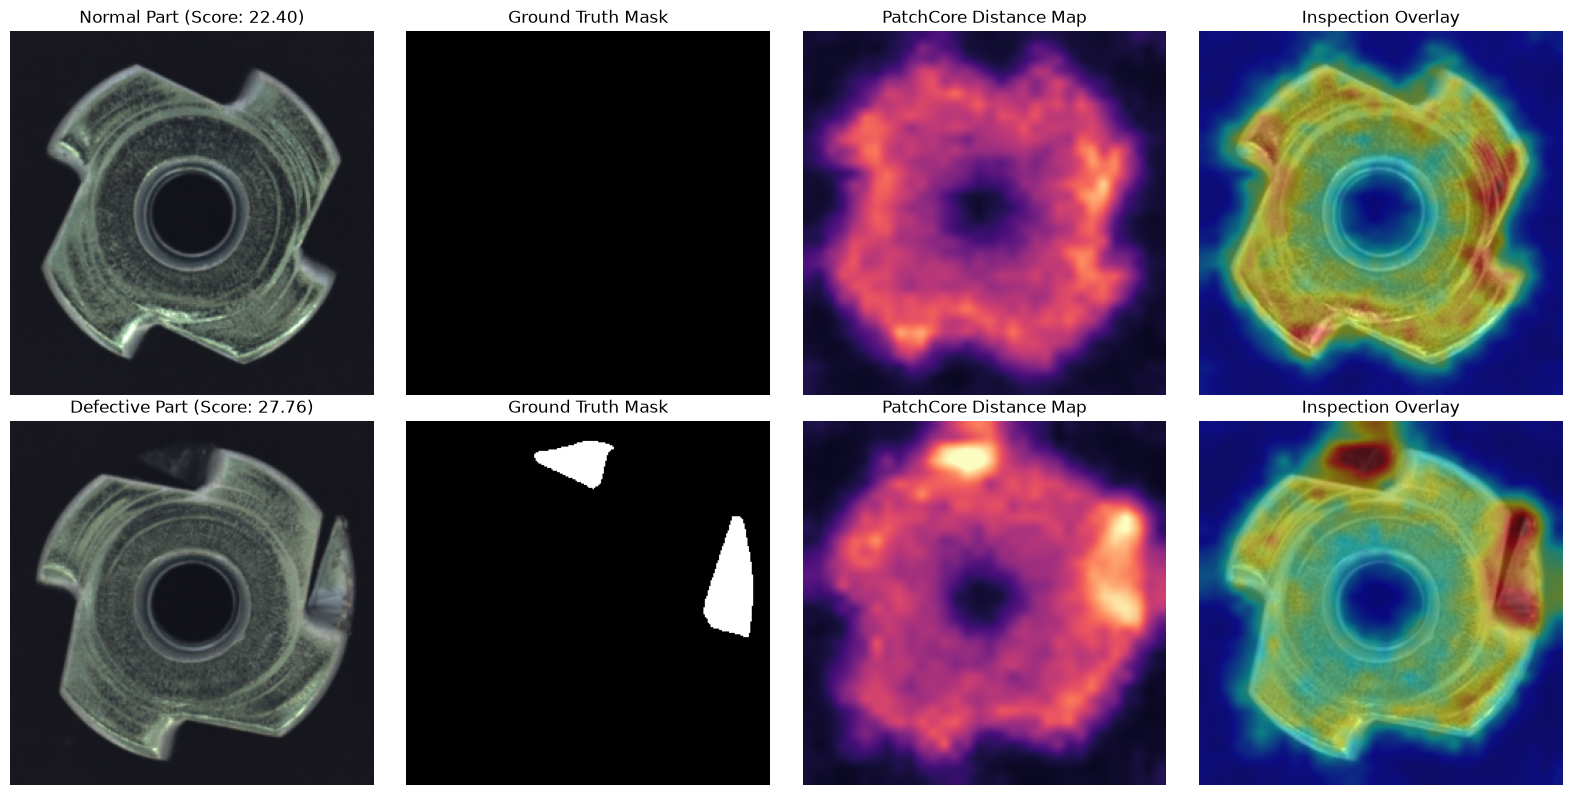

In [6]:
normal_idx = np.where(test_lbls == 0)[0][0]
defect_idx = np.where(test_lbls == 1)[0][0]

# Shared 99.5th percentile color scale so normal vs. defect heatmaps are directly comparable
vmax = float(np.percentile(patchcore_maps, 99.5))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, (idx, label_name) in enumerate([(normal_idx, "Normal Part"), (defect_idx, "Defective Part")]):
    norm_map = np.clip(patchcore_maps[idx] / (vmax + 1e-8), 0.0, 1.0)
    _, overlay_rgb = generate_heatmap_and_overlay(test_imgs[idx], norm_map, alpha=0.55)

    axes[row, 0].imshow(test_imgs[idx])
    axes[row, 0].set_title(f"{label_name} (Score: {patchcore_scores[idx]:.2f})")
    axes[row, 1].imshow(test_masks[idx], cmap="gray")
    axes[row, 1].set_title("Ground Truth Mask")
    axes[row, 2].imshow(patchcore_maps[idx], cmap="magma", vmin=0.0, vmax=vmax)
    axes[row, 2].set_title("PatchCore Distance Map")
    axes[row, 3].imshow(overlay_rgb)
    axes[row, 3].set_title("Inspection Overlay")

    for col in range(4):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## Milestone 04 Findings & Architectural Summary (`metal_nut`)

### 1. Benchmark Comparison: Autoencoder vs. PatchCore-Inspired Detection

| Architecture | Training / Fit Time | Normal Score (`mean ± std`) | Defect Score (`mean ± std`) | Image AUROC | Pixel AUROC | Avg Inference Latency |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **CNN Autoencoder (MSE Baseline)** | ~45s (50 epochs) | — | — | 25.61% | — | ~25 ms/img |
| **CNN Autoencoder (SSIM + MAE + Edge Mask)** | ~48s (50 epochs) | — | — | 30.21% | — | ~28 ms/img |
| **EfficientNetB0 + PatchCore Memory Bank** | **3.74s (zero epochs)** | **19.58 ± 1.12** | **25.75 ± 3.47** | **95.89%** | **98.31%** | **137.84 ms/img** |

---

### 2. Why PatchCore Outperforms Pixel Reconstruction on Industrial Parts
* **Rotation & Lighting Invariance:** MVTec `metal_nut` samples appear at arbitrary orientations with specular metallic glare. Pixel-level autoencoders penalize minor angular or lighting shifts as reconstruction errors, whereas PatchCore compares **locally-aggregated ($3 \times 3$ average-pooled) mid-level EfficientNetB0 feature descriptors** (`block2b_add` + `block3b_add`), matching normal brushed metal regardless of part rotation.
* **Fine Defect Localization (`98.31%` Pixel AUROC):** Because each $32 \times 32$ spatial grid cell carries a 64-dimensional multi-scale texture fingerprint, localized structural anomalies (bent flanges, scratches, missing notches) produce sharp nearest-neighbor distance spikes directly on the defect site without firing on background regions.

---

### 3. Documented Methodology Adaptations (PatchCore-Inspired Implementation)
Per VisionGuard AI engineering standards, the following intentional adaptations from Roth et al. (CVPR 2022) are documented for reproducibility and production latency:
1. **Backbone & Layer Selection:** Uses an ImageNet-pretrained, frozen **EfficientNetB0** tapping intermediate residual layers `block2b_add` (24 channels) and `block3b_add` (40 channels) aligned to a $32 \times 32$ grid (64-D patch vectors), chosen for fast CPU inference (~138 ms/image) over heavier WideResNet-50 backbones.
2. **Coreset Subsampling:** Uses seeded uniform-random subsampling (`coreset_ratio=0.10`, `seed=42`, yielding **19,148** nominal vectors) rather than iterative greedy minimax $k$-center selection, reducing memory-bank construction time from minutes to **3.74 seconds**.
3. **Anomaly Scoring:** Computes exact Euclidean ($L_2$) nearest-neighbor distance (`n_neighbors=1`) and takes the spatial maximum (`np.max`) across the $32 \times 32$ patch distance grid without neighborhood density re-weighting.


